In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('laptops.csv')

# **EDA**

In [ ]:
df.isna().sum()

Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   str    
 1   Status        2160 non-null   str    
 2   Brand         2160 non-null   str    
 3   Model         2160 non-null   str    
 4   CPU           2160 non-null   str    
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2118 non-null   str    
 8   GPU           789 non-null    str    
 9   Screen        2156 non-null   float64
 10  Touch         2160 non-null   str    
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(2), str(8)
memory usage: 429.7 KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.head()

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,Asus,ExpertBook,Intel Core i5,8,512,SSD,NaN,15.6,No,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,NaN,15.6,No,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,Asus,ExpertBook,Intel Core i3,8,256,SSD,NaN,15.6,No,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,MSI,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,NaN,15.6,No,669.01


In [ ]:
print("Shape:", df.shape)

Shape: (2160, 12)


In [ ]:
target = 'Final Price'

q1, q3 = df[target].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df[target] < low) | (df[target] > high)]
print(f"Bounds: {low:.0f} to {high:.0f}")
print(f"Outliers: {len(outliers)} rows ({len(outliers)/len(df)*100:.1f}%)")
display(outliers.sort_values(target, ascending=False).head(10))

Bounds: -911 to 3281
Outliers: 103 rows (4.8%)


,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
1099,MSI Raider GE78HX 13VH-065ES Intel Core i9-139...,New,MSI,Raider,Intel Core i9,32,2000,SSD,RTX 4080,17.0,No,7150.47
478,MSI Titan GT77 HX 13VI-006ES Intel Core i9-139...,New,MSI,Titan,Intel Core i9,128,2000,SSD,RTX 4090,17.3,No,5999.00
1202,ASUS ROG Strix SCAR 18 G834JY-93B49PB1 Intel C...,New,Asus,ROG,Intel Core i9,64,2000,SSD,RTX 4090,16.0,No,5758.14
1245,ASUS ROG Strix Scar 17 G733PY-R97B49PB1 AMD R...,New,Asus,ROG,AMD Radeon 9,32,2000,SSD,RTX 4090,17.3,No,5630.90
1475,HP ZBook Studio G8 Intel Core i7-11850H/16GB/5...,New,HP,Zbook,Intel Core i7,16,512,SSD,RTX A3000,15.6,No,5368.77
952,MSI Raider GE78HX 13VI-063ES Intel Core i9-139...,New,MSI,Raider,Intel Core i9,64,2000,SSD,RTX 4090,17.0,No,5199.00
495,ASUS ROG Zephyrus Duo 16 2023 GX650PY-NM003W A...,New,Asus,ROG,AMD Ryzen 9,64,2000,SSD,RTX 4090,16.0,No,5159.00
1511,Lenovo Legion PRO 7 16IRX8H-566 Intel Core i9-...,New,Lenovo,Legion,Intel Core i9,32,1000,SSD,RTX 4080,16.0,No,5018.14
550,Razer Blade 16 Doble Resolución UHD+/FHD+ Inte...,New,Razer,Blade,Intel Core i9,32,2000,SSD,RTX 4090,16.0,No,4999.01
2128,MSI Titan GT77 12UHS-021ES Intel Core i9-12900...,Refurbished,MSI,Titan,Intel Core i9,64,2000,SSD,RTX 3080,17.3,No,4999.00


In [ ]:
for c in df.columns:
    print(f"\n--- {c}: {df[c].nunique()} unique ---")
    print(df[c].unique())


--- Laptop: 2160 unique ---
<ArrowStringArray>
[        'ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core i5-1235U/8GB/512GB SSD/15.6"',
                             'Alurin Go Start Intel Celeron N4020/8GB/256GB SSD/15.6"',
         'ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core i3-1215U/8GB/256GB SSD/15.6"',
         'MSI Katana GF66 12UC-082XES Intel Core i7-12700H/16GB/1TB SSD/RTX3050/15.6"',
                            'HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB SSD/15.6"',
      'MSI Crosshair 17 C12VF-264XES Intel Core i7-12650H/32GB/1TB SSD/RTX 4060/17.3"',
                       'Lenovo Thinkpad E14 Gen 4 AMD Ryzen 5 5625U/8GB/256GB SSD/14"',
            'ASUS VivoBook 15 F515JA-EJ2882W Intel Core i7-1065G7/8GB/512GB SSD/15.6"',
                        'Medion Akoya E15415 Intel Core i5-10210U/8GB/256GB SSD/15.6"',
             'HP Victus 16-d1038ns Intel Core i7-12700H/16GB/512GB SSD/RTX 3050/16.1"',
 ...
 'Razer Blade 15 Advanced Model QHD Intel Core i7-11800H/32 GB/1TB 

In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns

for c in cat_cols:
    print(f"\n--- {c}: {df[c].nunique()} unique values ---")
    print(df[c].value_counts().head(8))


--- Laptop: 2160 unique values ---
Laptop
ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core i5-1235U/8GB/512GB SSD/15.6"       1
Alurin Go Start Intel Celeron N4020/8GB/256GB SSD/15.6"                           1
ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core i3-1215U/8GB/256GB SSD/15.6"       1
MSI Katana GF66 12UC-082XES Intel Core i7-12700H/16GB/1TB SSD/RTX3050/15.6"       1
HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB SSD/15.6"                          1
MSI Crosshair 17 C12VF-264XES Intel Core i7-12650H/32GB/1TB SSD/RTX 4060/17.3"    1
Lenovo Thinkpad E14 Gen 4 AMD Ryzen 5 5625U/8GB/256GB SSD/14"                     1
ASUS VivoBook 15 F515JA-EJ2882W Intel Core i7-1065G7/8GB/512GB SSD/15.6"          1
Name: count, dtype: int64

--- Status: 2 unique values ---
Status
New            1498
Refurbished     662
Name: count, dtype: int64

--- Brand: 27 unique values ---
Brand
Asus         415
HP           368
Lenovo       366
MSI          308
Acer         137
Apple        116
Dell        

C:\Users\engyw\AppData\Local\Temp\ipykernel_8412\1524643407.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [ ]:
df["Brand"].value_counts()
df["Brand"].value_counts(normalize=True) * 100
df["Final Price"].skew()

np.float64(1.6495877663192549)

In [ ]:
df[df['Final Price']<0]

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price


In [ ]:
missing_pct = df.isnull().mean() * 100
print(missing_pct[missing_pct > 0].sort_values(ascending=False))

GPU             63.472222
Storage type     1.944444
Screen           0.185185
dtype: float64


# **Data visualization**

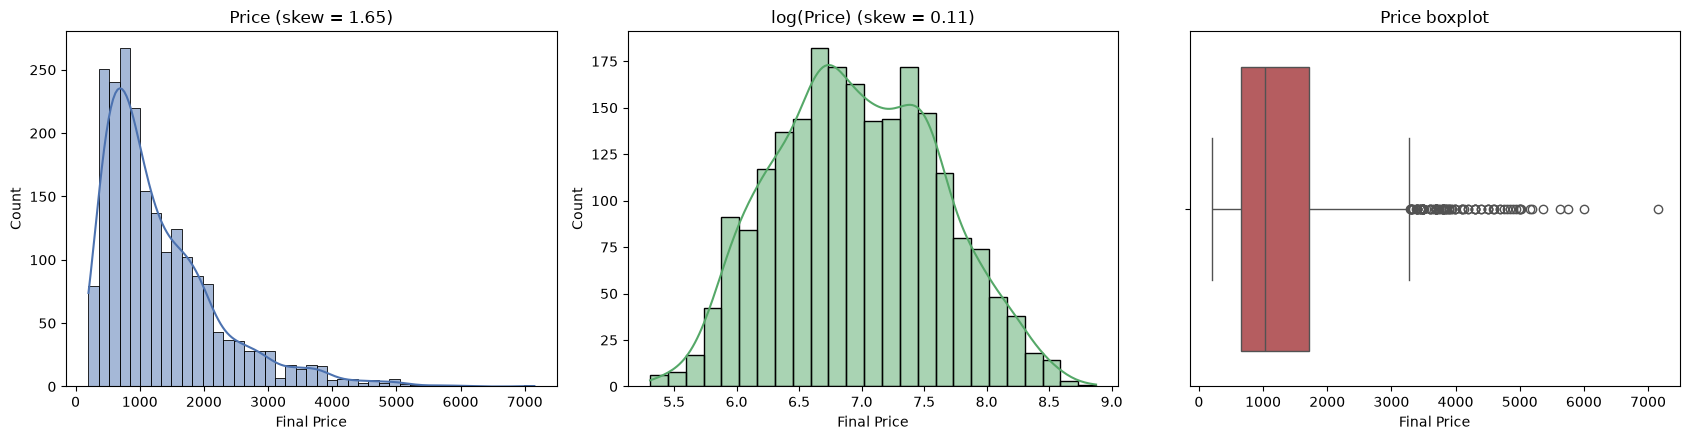

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df['Final Price'], kde=True, ax=ax[0], color="#4C72B0")
ax[0].set_title(f"Price (skew = {df['Final Price'].skew():.2f})")
sns.histplot(np.log1p(df['Final Price']), kde=True, ax=ax[1], color="#55A868")
ax[1].set_title(f"log(Price) (skew = {np.log1p(df['Final Price']).skew():.2f})")
sns.boxplot(x=df['Final Price'], ax=ax[2], color="#C44E52")
ax[2].set_title("Price boxplot")
plt.tight_layout(); plt.show()

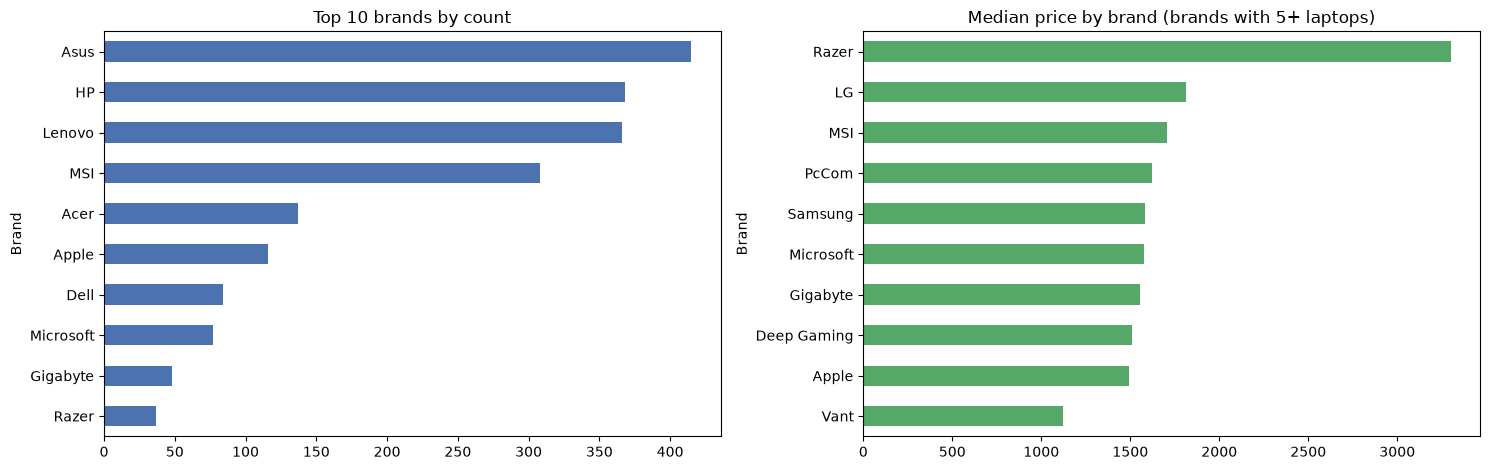

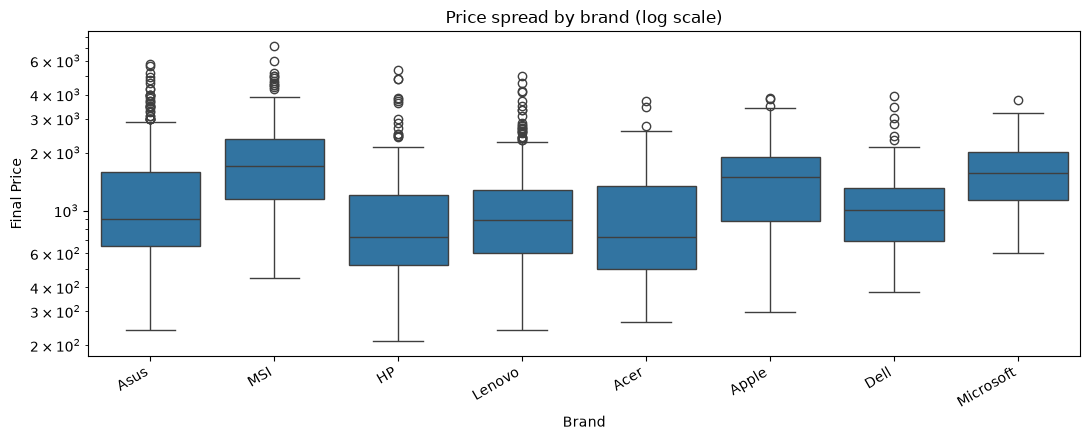

In [ ]:
brand_col = 'Brand'
price_col = 'Final Price'

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
df[brand_col].value_counts().head(10).sort_values().plot(kind="barh", ax=ax[0], color="#4C72B0")
ax[0].set_title("Top 10 brands by count")

med = df.groupby(brand_col)[price_col].agg(["median", "count"])
med = med[med["count"] >= 5].sort_values("median").tail(10)
med["median"].plot(kind="barh", ax=ax[1], color="#55A868")
ax[1].set_title("Median price by brand (brands with 5+ laptops)")
plt.tight_layout(); plt.show()

top_brands = df[brand_col].value_counts().head(8).index
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=df[df[brand_col].isin(top_brands)], x=brand_col, y=price_col)
plt.yscale("log"); plt.xticks(rotation=30, ha="right")
plt.title("Price spread by brand (log scale)")
plt.tight_layout(); plt.show()

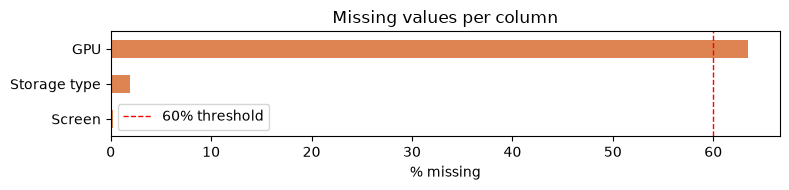

In [ ]:
miss = (df.isnull().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
if len(miss):
    plt.figure(figsize=(8, max(2, 0.5 * len(miss))))
    miss.sort_values().plot(kind="barh", color="#DD8452")
    plt.axvline(60, color="red", ls="--", lw=1, label="60% threshold")
    plt.xlabel("% missing"); plt.title("Missing values per column"); plt.legend()
    plt.tight_layout(); plt.show()
else:
    print("No missing values.")

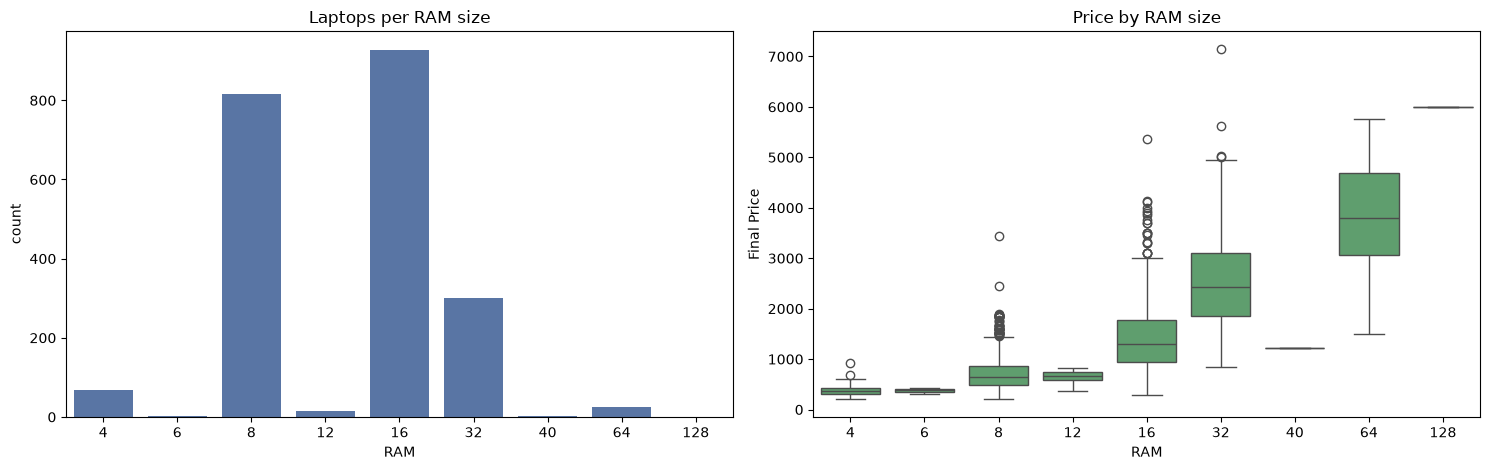

In [ ]:
ram_col = 'RAM'
price_col = 'Final Price'

if pd.api.types.is_numeric_dtype(df[ram_col]):
    order = sorted(df[ram_col].dropna().unique())
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
    sns.countplot(data=df, x=ram_col, order=order, ax=ax[0], color="#4C72B0")
    ax[0].set_title("Laptops per RAM size")
    sns.boxplot(data=df, x=ram_col, y=price_col, order=order, ax=ax[1], color="#55A868")
    ax[1].set_title("Price by RAM size")
    plt.tight_layout(); plt.show()
else:
    print("RAM is text, clean it to numbers first, then rerun this cell.")

GPU
No GPU     63.5 %
Has GPU    36.5 %
Name: proportion, dtype: str


C:\Users\engyw\AppData\Local\Temp\ipykernel_8412\4033379797.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=tmp, x="has_gpu", ax=ax[0], palette=["#4C72B0", "#DD8452"])
C:\Users\engyw\AppData\Local\Temp\ipykernel_8412\4033379797.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tmp, x="has_gpu", y=price_col, ax=ax[1], palette=["#4C72B0", "#DD8452"])


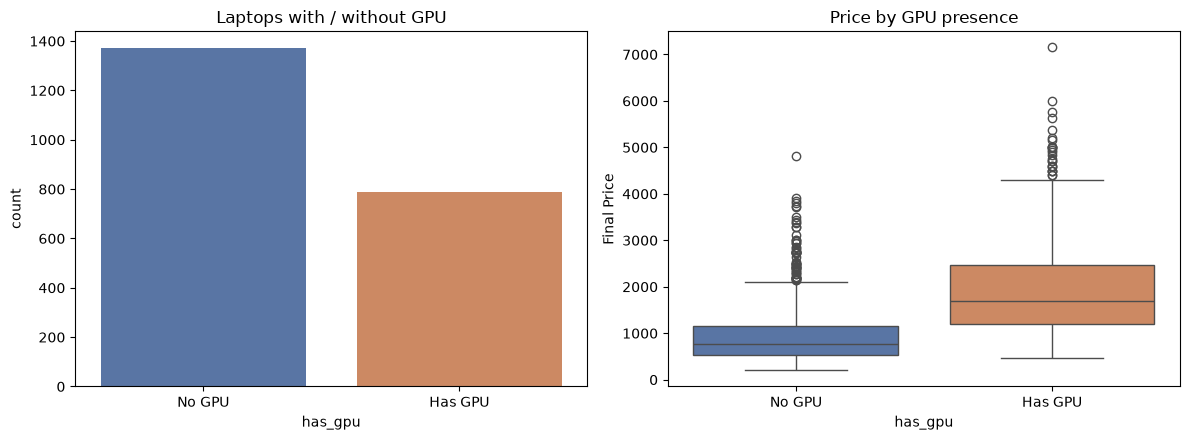

         count    mean  median
has_gpu                       
Has GPU    789  1957.0  1699.0
No GPU    1371   942.0   770.0


In [ ]:
gpu_col = 'GPU'
price_col = 'Final Price'

if gpu_col in df.columns:
    has = (df[gpu_col].notna() & (df[gpu_col].astype(str) != "No GPU")).map(
        {True: "Has GPU", False: "No GPU"})
    print(has.value_counts(normalize=True).mul(100).round(1).astype(str) + " %")

    tmp = df.assign(has_gpu=has)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.countplot(data=tmp, x="has_gpu", ax=ax[0], palette=["#4C72B0", "#DD8452"])
    ax[0].set_title("Laptops with / without GPU")
    sns.boxplot(data=tmp, x="has_gpu", y=price_col, ax=ax[1], palette=["#4C72B0", "#DD8452"])
    ax[1].set_title("Price by GPU presence")
    plt.tight_layout(); plt.show()
    print(tmp.groupby("has_gpu")[price_col].agg(["count", "mean", "median" ]).round(0))

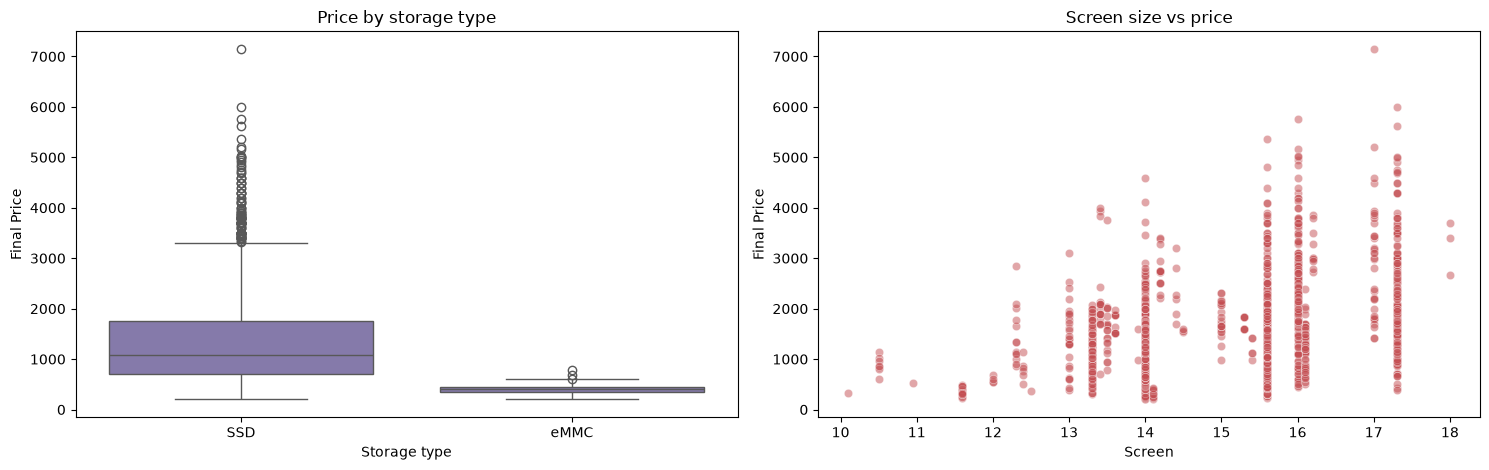

In [ ]:
stype_col = 'Storage type'
price_col = 'Final Price'
screen_col = 'Screen'

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
if stype_col in df.columns:
    sns.boxplot(data=df, x=stype_col, y=price_col, ax=ax[0], color="#8172B2")
    ax[0].set_title("Price by storage type")
else:
    ax[0].axis("off")
if screen_col in df.columns and pd.api.types.is_numeric_dtype(df[screen_col]):
    sns.scatterplot(data=df, x=screen_col, y=price_col, alpha=0.5, ax=ax[1], color="#C44E52")
    ax[1].set_title("Screen size vs price")
else:
    ax[1].axis("off")
plt.tight_layout(); plt.show()

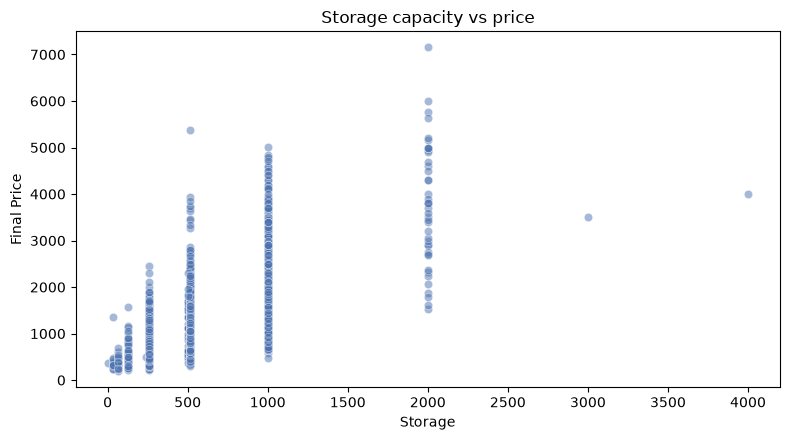

In [ ]:
storage_col = 'Storage'
price_col = 'Final Price'

if storage_col in df.columns and pd.api.types.is_numeric_dtype(df[storage_col]):
    plt.figure(figsize=(8, 4.5))
    sns.scatterplot(data=df, x=storage_col, y=price_col, alpha=0.5, color="#4C72B0")
    plt.title("Storage capacity vs price")
    plt.tight_layout(); plt.show()
elif storage_col in df.columns:
    print("Storage is text, clean it to numbers first, then rerun this cell.")

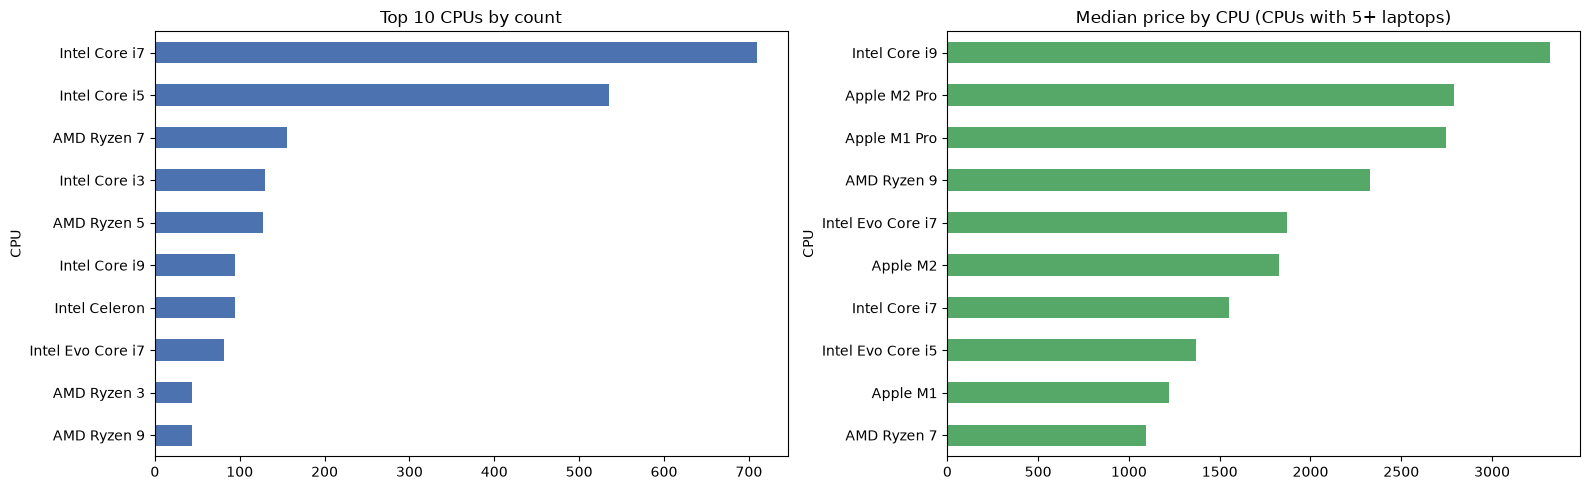

In [ ]:
cpu_col = 'CPU'
price_col = 'Final Price'

if cpu_col in df.columns:
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    df[cpu_col].value_counts().head(10).sort_values().plot(kind="barh", ax=ax[0], color="#4C72B0")
    ax[0].set_title("Top 10 CPUs by count")

    med = df.groupby(cpu_col)[price_col].agg(["median", "count"])
    med = med[med["count"] >= 5].sort_values("median").tail(10)
    med["median"].plot(kind="barh", ax=ax[1], color="#55A868")
    ax[1].set_title("Median price by CPU (CPUs with 5+ laptops)")
    plt.tight_layout(); plt.show()

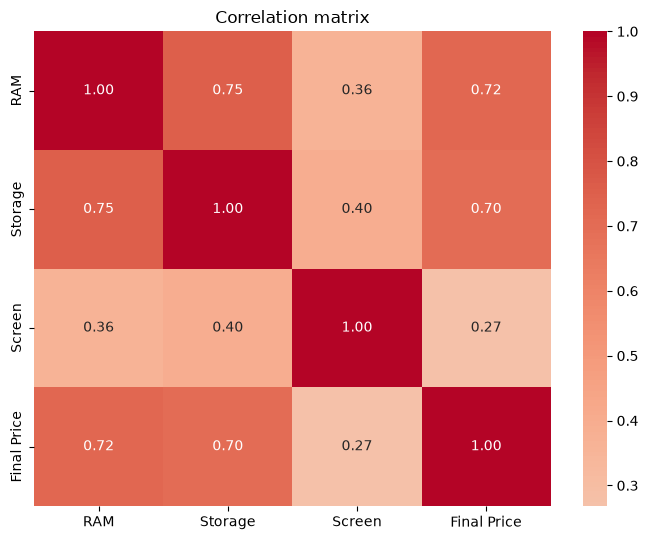

In [ ]:
num = df.select_dtypes(include="number")
if num.shape[1] > 1:
    plt.figure(figsize=(7, 5.5))
    sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation matrix")
    plt.tight_layout(); plt.show()
else:
    print("Only one numeric column, nothing to correlate yet.")

In [ ]:
price_col = 'Final Price'

print("Top 10 most expensive:")
display(df.sort_values(price_col, ascending=False).head(10))
print("Top 10 cheapest:")
display(df.sort_values(price_col).head(10))

Top 10 most expensive:


,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
1099,MSI Raider GE78HX 13VH-065ES Intel Core i9-139...,New,MSI,Raider,Intel Core i9,32,2000,SSD,RTX 4080,17.0,No,7150.47
478,MSI Titan GT77 HX 13VI-006ES Intel Core i9-139...,New,MSI,Titan,Intel Core i9,128,2000,SSD,RTX 4090,17.3,No,5999.00
1202,ASUS ROG Strix SCAR 18 G834JY-93B49PB1 Intel C...,New,Asus,ROG,Intel Core i9,64,2000,SSD,RTX 4090,16.0,No,5758.14
1245,ASUS ROG Strix Scar 17 G733PY-R97B49PB1 AMD R...,New,Asus,ROG,AMD Radeon 9,32,2000,SSD,RTX 4090,17.3,No,5630.90
1475,HP ZBook Studio G8 Intel Core i7-11850H/16GB/5...,New,HP,Zbook,Intel Core i7,16,512,SSD,RTX A3000,15.6,No,5368.77
952,MSI Raider GE78HX 13VI-063ES Intel Core i9-139...,New,MSI,Raider,Intel Core i9,64,2000,SSD,RTX 4090,17.0,No,5199.00
495,ASUS ROG Zephyrus Duo 16 2023 GX650PY-NM003W A...,New,Asus,ROG,AMD Ryzen 9,64,2000,SSD,RTX 4090,16.0,No,5159.00
1511,Lenovo Legion PRO 7 16IRX8H-566 Intel Core i9-...,New,Lenovo,Legion,Intel Core i9,32,1000,SSD,RTX 4080,16.0,No,5018.14
550,Razer Blade 16 Doble Resolución UHD+/FHD+ Inte...,New,Razer,Blade,Intel Core i9,32,2000,SSD,RTX 4090,16.0,No,4999.01
2128,MSI Titan GT77 12UHS-021ES Intel Core i9-12900...,Refurbished,MSI,Titan,Intel Core i9,64,2000,SSD,RTX 3080,17.3,No,4999.00


Top 10 cheapest:


,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
668,Thomson Neo White Intel Celeron N4020/4GB/64GB...,New,Thomson,Neo,Intel Celeron,4,64,eMMC,NaN,14.1,No,201.05
505,Primux ioxbook 1406F Intel Celeron N4000/4 GB/...,New,Primux,Ioxbook,Intel Celeron,4,128,SSD,NaN,14.0,No,208.99
638,HP EliteBook 840 G3 Intel Core i5-6200U/8GB/25...,Refurbished,HP,EliteBook,Intel Core i5,8,256,SSD,NaN,14.0,No,210.14
554,Primux Ioxbook 15CA Intel Celeron N4000/8GB/25...,New,Primux,Ioxbook,Intel Celeron,8,256,SSD,NaN,15.6,No,229.00
728,HP Chromebook 11 G9 Intel Celeron N4500/4GB/32...,New,HP,Chromebook,Intel Celeron,4,32,NaN,NaN,11.6,No,230.14
886,Thomson Neo Black Intel Celeron N4020/4GB/64GB...,New,Thomson,Neo,Intel Celeron,4,64,eMMC,NaN,14.1,No,230.83
26,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,NaN,14.0,No,239.00
813,Lenovo ThinkPad L450 Intel Core i5-4300U/8GB/2...,Refurbished,Lenovo,ThinkPad,Intel Core i5,8,256,SSD,NaN,14.0,No,239.00
961,Asus Chromebook C204MA-GJ0342 Intel Celeron N4...,New,Asus,Chromebook,Intel Celeron,4,32,eMMC,NaN,11.6,No,239.25
2133,Medion Akoya E4251 Intel Celeron N4020/4GB/64G...,Refurbished,Medion,Akoya,Intel Celeron,4,64,NaN,NaN,14.0,No,246.89


# ***Data cleaning and preprocessing***

In [ ]:
try:
    df
except NameError:
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0])

TARGET = "Final Price"
print("Before cleaning:", df.shape)

Before cleaning: (2160, 12)


In [ ]:
print("Duplicates removed:", df.duplicated().sum())
df = df.drop_duplicates()


Duplicates removed: 0


In [ ]:
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

C:\Users\engyw\AppData\Local\Temp\ipykernel_8412\779005343.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df.select_dtypes(include="object").columns:


In [ ]:
df = df.dropna(subset=[TARGET])
df = df[df[TARGET] > 0]

In [ ]:
df = df.dropna(subset=["Screen"])

In [ ]:
df["has_gpu"] = (df["GPU"].notnull() & (df["GPU"] != "No GPU")).astype(int)
df["GPU"] = df["GPU"].fillna("No GPU")
print("has_gpu:\n", df["has_gpu"].value_counts(normalize=True).round(3))

has_gpu:
 has_gpu
0    0.635
1    0.365
Name: proportion, dtype: float64


In [ ]:

print("Storage == 0:", (df["Storage"] == 0).sum())

print("After cleaning:", df.shape)
print("Missing values left:\n", df.isnull().sum()[df.isnull().sum() > 0])

Storage == 0: 1
After cleaning: (2156, 13)
Missing values left:
 Storage type    42
dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error

In [ ]:
NUM = ['RAM', 'Storage', 'Screen', 'has_gpu']
CAT = ['Laptop', 'Status', 'Brand', 'Model', 'CPU', 'Storage type', 'GPU']
BIN = ['Touch']

In [ ]:


def make_prep(poly=False):
    num_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]
    if poly:
        num_steps.append(
            ("poly", PolynomialFeatures(degree=2, include_bias=False))
        )
    num_steps.append(("scaler", StandardScaler()))

    try:
        encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse=False)

    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", encoder)
        ]), CAT),
        ("bin", SimpleImputer(strategy="most_frequent"), BIN)
    ])

models = {
    "Simple Linear Regression": (
        LinearRegression(),
        ColumnTransformer([
            ("ram", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), ["RAM"])
        ], remainder="drop")
    ),
    "Multiple Linear Regression": (
        LinearRegression(), make_prep()
    ),
    "Polynomial Regression": (
        LinearRegression(), make_prep(poly=True)
    ),
    "Ridge Regression": (
        Ridge(alpha=1), make_prep()
    ),
    "Lasso Regression": (
        Lasso(alpha=0.001, max_iter=10000), make_prep()
    ),
    "SVR": (
        SVR(C=10, kernel="rbf"), make_prep()
    ),
    "Decision Tree Regression": (
        DecisionTreeRegressor(
            max_depth=8,
            min_samples_leaf=5,
            random_state=42
        ),
        make_prep()
    ),
    "Random Forest Regression": (
        RandomForestRegressor(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ),
        make_prep()
    )
}

In [ ]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=[TARGET])
y = df[TARGET]



X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
print(X_train.columns.tolist())

['Laptop', 'Status', 'Brand', 'Model', 'CPU', 'RAM', 'Storage', 'Storage type', 'GPU', 'Screen', 'Touch', 'has_gpu']


In [ ]:
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, (model, preprocessor) in models.items():
    try:
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", model)
        ])

        scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)
        mean_score = scores.mean()
        std_score = scores.std()

        results.append({
            "Model": name,
            "R2_Mean": mean_score,
            "R2_Std": std_score
        })
        print(f"{name} -> R2 Mean: {mean_score:.4f} (+/- {std_score:.4f})")
        
    except Exception as e:
        print(f"❌ Error with model '{name}': {e}")

Simple Linear Regression -> R2 Mean: 0.5284 (+/- 0.0313)
❌ Error with model 'Multiple Linear Regression': 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\engyw\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\engyw\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\engyw\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\pipeline.py", line 649, in fit
    self._fina

In [ ]:
results_df = pd.DataFrame(results).sort_values(by="R2_Mean", ascending=False).reset_index(drop=True)

print(results_df)

                      Model   R2_Mean    R2_Std
0  Simple Linear Regression  0.528364  0.031281


In [ ]:
best_model_name = results_df.loc[0, "Model"]
print(f"\n Best model:  **{best_model_name}**")

best_estimator, best_preprocessor = models[best_model_name]
best_pipeline = Pipeline([
    ("preprocessor", best_preprocessor),
    ("model", best_estimator)
])

best_pipeline.fit(X_train, y_train)



 Best model:  **Simple Linear Regression**


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Laptop','Status','Brand',...,'Screen','Touch','has_gpu']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ram', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the ou

In [ ]:
from sklearn.metrics import mean_squared_error

y_pred = best_pipeline.predict(X_test)

print("\n---Evaluate the best model (Test Set) ---")
print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")


---Evaluate the best model (Test Set) ---
R2 Score: 0.5020
MAE: 463.9588
RMSE: 652.8852


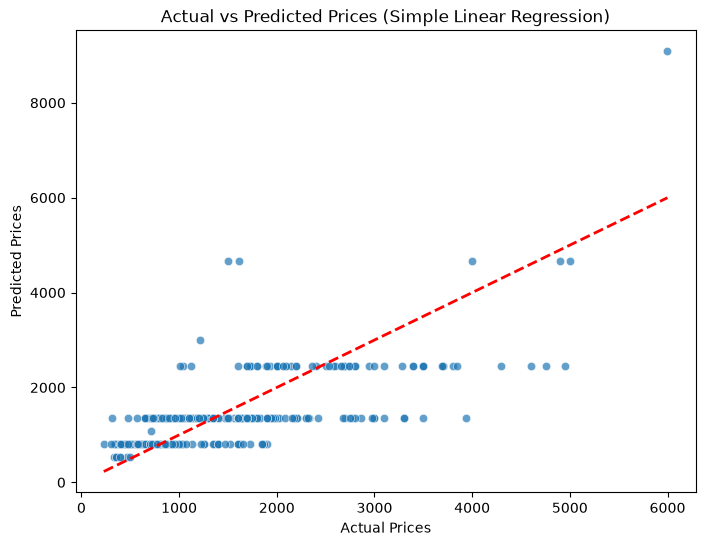

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title(f"Actual vs Predicted Prices ({best_model_name})")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.show()

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def make_prep():
    all_cat_cols = CAT + BIN 
    
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), NUM),
        
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), all_cat_cols)
    ], remainder="drop")

In [ ]:
# from sklearn.ensemble import VotingRegressor
# from sklearn.pipeline import Pipeline

# ridge_model = Ridge(alpha=1)
# rf_model = RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_leaf=3, random_state=42, n_jobs=-1)


# voting_regressor = VotingRegressor(
#     estimators=[
#         ('ridge', ridge_model),
#         ('rf', rf_model)
#     ]
# )

# final_pipeline = Pipeline([
#     ("preprocessor", make_prep()),
#     ("model", voting_regressor)
# ])

# cv_scores = cross_val_score(final_pipeline, X_train, y_train, cv=5, scoring="r2", n_jobs=-1)
# print(f"Voting Regressor R2 Mean: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

In [ ]:
from sklearn.ensemble import VotingRegressor

ridge_pipeline = Pipeline([
    ("preprocessor", make_prep()),
    ("model", Ridge(alpha=1))
])

rf_pipeline = Pipeline([
    ("preprocessor", make_prep()),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

lr_pipeline = Pipeline([
    ("preprocessor", make_prep()),
    ("model", LinearRegression())
])


In [ ]:

voting_regressor = VotingRegressor(
    estimators=[
        ('ridge', ridge_pipeline),
        ('rf', rf_pipeline),
        ('lr', lr_pipeline)
    ]
)


In [ ]:
cv_scores = cross_val_score(voting_regressor, X_train, y_train, cv=5, scoring="r2", n_jobs=-1)
print(f"Voting Regressor R2 Mean: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

Voting Regressor R2 Mean: 0.8363 (+/- 0.0210)


In [ ]:
voting_regressor.fit(X_train, y_train)

y_pred_voting = voting_regressor.predict(X_test)

print("\n--- Evaluating Voting Regressor on Test Set ---")
print(f"R2 Score: {r2_score(y_test, y_pred_voting):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_voting):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_voting)):.4f}")


--- Evaluating Voting Regressor on Test Set ---
R2 Score: 0.9038
MAE: 206.7006
RMSE: 286.9011


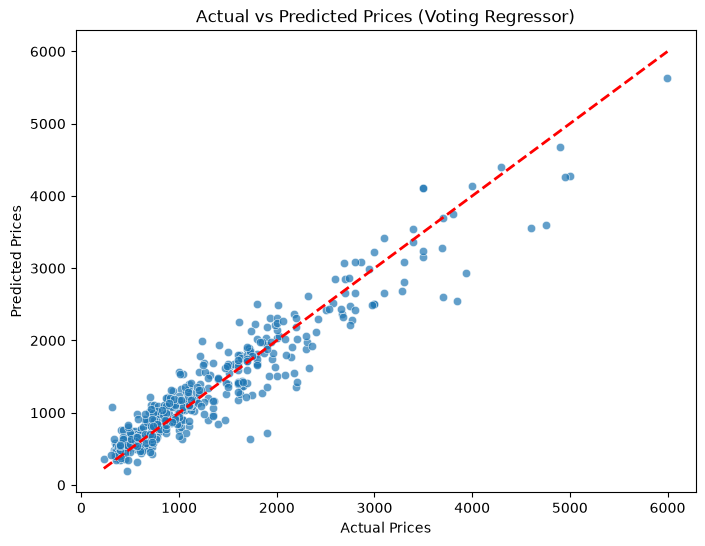

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred_voting, alpha=0.7)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices (Voting Regressor)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.show()

In [ ]:
import joblib

joblib.dump(final_pipeline, 'laptop_price_model.pkl')
print("Model saved successfully as 'laptop_price_model.pkl'!")

Model saved successfully as 'laptop_price_model.pkl'!


: 